In [1]:
import matplotlib.pyplot as plt
import sys
sys.path.append('../')
from utils import plotting_utils
import pickle
import jax.numpy as jnp
import pickle as pkl
import interpax as ipx
from datetime import datetime, timedelta

In [2]:
parameterization = "drying" # permaFoam_omega50, drying, drying_omega10, cap

input_folder =  "../input/era5_land_data/Sweden/"
input_filename = "sim_2312_2405.pkl"
# input_filename = "spinup_2308_2311.pkl"

# sim_folder = "../output/Simulations_Paper/ERA5_Sweden/simulations/"
# sim_filename = f"simulation_{parameterization}.pkl"

# save_folder = "../figures/Simulations_Paper/ERA5_Sweden/Winter2024/" 
# save_filename = f"simulation_{parameterization}"

sim_folder = "../output/Simulations_Paper/Constant/"
sim_filename = f"{parameterization}.pkl"

save_folder = "../figures/Simulations_Paper/Constant/" 
save_filename = f"streamplot_{parameterization}"

with open(sim_folder+sim_filename, 'rb') as pickle_file:
    db = pickle.load(pickle_file)

time_array = jnp.array(db["time_array"])
time = 90*24*60*60
idx = jnp.argmin(jnp.abs(time_array-time))
print(time_array[-1]/24/60/60)


60.012184


In [3]:
# if input_folder is not None and input_filename is not None:
#     with open(input_folder + input_filename, "rb") as f:
#         db_input = pkl.load(f)
#         dates = [db_input["dates"][0] + timedelta(seconds=float(t)) for t in db['time_array']]
#         t_bc = db_input["time"]
#         t_bc = t_bc - t_bc[0]
#         T_surface = db_input["skt"]
#         q_inf = db_input["recharge"]
#         T_surface_interp = ipx.Interpolator1D(t_bc, T_surface,method="cubic2")
#         recharge_interp = ipx.Interpolator1D(t_bc, q_inf,method="cubic2")

#         recharge = recharge_interp(db['time_array'])
#         T_surface = T_surface_interp(db['time_array'])
#         q_runoff = jnp.sum(jnp.array(db["q_runoff"]),axis=1)/jnp.array(db["q_runoff"]).shape[1]
#         q_inf = recharge - q_runoff
#         print(jnp.shape(recharge), jnp.shape(T_surface), jnp.shape(q_inf),jnp.shape(db['time_array']), len(dates))


# else: 
#     time = jnp.array(db["time_array"])
#     recharge = 2e-8*jnp.ones_like(time)
#     T_surface = -5*jnp.ones_like(time)

#     q_runoff = jnp.sum(jnp.array(db["q_runoff"]),axis=1)/jnp.array(db["q_runoff"]).shape[1]
#     q_inf = recharge - q_runoff
#     ani, fig, ax = plotting_utils.create_animation_streamlines(db['X'], db['Z'], db['theta_l_total'], db['qx_centered_array'], db['qz_centered_array'],  db['theta_i_total'],  db['T_total'],recharge,q_inf, T_surface, time, slope=-0.1, density=1, linewidth = 4, cmaps=('Blues', 'bone_r','coolwarm'), clabels=(r'$\theta_l$ [-]', r'$\theta_i$ [-]',r'$T[°C]$'),cmap_stream="magma",arrowsize=0)

/home/anne/Dokumente/Promotion/Code/FrozenSoil_AD/notebooks/../utils/plotting_utils.py:211: RuntimeWarning: divide by zero encountered in log10
  lw = np.log10(speed) - np.nanmin(np.log10(speed))
/home/anne/Dokumente/Promotion/Code/FrozenSoil_AD/notebooks/../utils/plotting_utils.py:211: RuntimeWarning: invalid value encountered in subtract
  lw = np.log10(speed) - np.nanmin(np.log10(speed))
/home/anne/Dokumente/Promotion/Code/FrozenSoil_AD/notebooks/../utils/plotting_utils.py:212: RuntimeWarning: invalid value encountered in divide
  lw = lw / np.nanmax(lw) * linewidth
/home/anne/Dokumente/Promotion/Code/FrozenSoil_AD/notebooks/../utils/plotting_utils.py:246: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


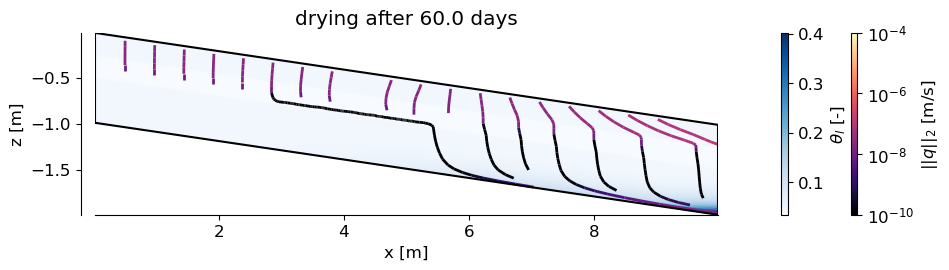

In [4]:
fig,ax = plotting_utils.plot_streamlines(db['X'], db['Z'], db['qx_centered_array'][idx], db['qz_centered_array'][idx], slope=-0.1, field=db['theta_l_total'][idx], cmap="Blues", title=f"{parameterization} after {jnp.round(time_array[idx]/24/60/60)} days",
                     xlabel="x [m]", ylabel="z [m]",
                     density=1.0, color="k", linewidth=2.0, arrowsize=1,cmap_stream="magma")

In [5]:
fig.savefig(save_folder+save_filename+".png",dpi=300,transparent=True)